In [1]:
# ============================================================
# CELL 1 — IMPORT LIBRARIES
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
import os

from lime.lime_tabular import LimeTabularExplainer

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
# ============================================================
# CELL 2 — DEFINE PATHS
# ============================================================

BASE_DIR = os.path.abspath(
    os.path.join(os.getcwd(), "..")
)

PROCESSED_DIR = os.path.join(
    BASE_DIR,
    "datasets",
    "processed",
    "stroke"
)

MODEL_DIR = os.path.join(
    BASE_DIR,
    "models",
    "stroke"
)

print("Processed directory:", PROCESSED_DIR)
print("Model directory:", MODEL_DIR)

Processed directory: d:\Explainable-AI-CDSS\datasets\processed\stroke
Model directory: d:\Explainable-AI-CDSS\models\stroke


In [4]:
# ============================================================
# CELL 3 — LOAD PROCESSED DATA
# ============================================================

X_train = pd.read_csv(
    os.path.join(PROCESSED_DIR, "x_train.csv")
)

X_test = pd.read_csv(
    os.path.join(PROCESSED_DIR, "x_test.csv")
)

y_train = pd.read_csv(
    os.path.join(PROCESSED_DIR, "y_train.csv")
).squeeze()

y_test = pd.read_csv(
    os.path.join(PROCESSED_DIR, "y_test.csv")
).squeeze()

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (4088, 21)
X_test: (1022, 21)


In [5]:
# ============================================================
# CELL 4 — LOAD MODEL AND ARTIFACTS
# ============================================================

model = joblib.load(
    os.path.join(MODEL_DIR, "best_model.pkl")
)

scaler = joblib.load(
    os.path.join(MODEL_DIR, "scaler.pkl")
)

feature_names = joblib.load(
    os.path.join(MODEL_DIR, "feature_names.pkl")
)

print("Model:", type(model).__name__)
print("Number of features:", len(feature_names))

Model: LogisticRegression
Number of features: 21


In [6]:
# ============================================================
# CELL 5 — CREATE LIME EXPLAINER
# ============================================================

explainer = LimeTabularExplainer(
    training_data=X_train.values,
    feature_names=list(feature_names),
    class_names=["No Stroke", "Stroke"],
    mode="classification",
    discretize_continuous=True,
    random_state=42
)

print("LIME explainer created successfully.")

LIME explainer created successfully.


In [7]:
# Verify saved CKD models

print("Checking saved CKD model files:\n")

for file_name in [
    "logistic_regression.pkl",
    "decision_tree.pkl",
    "random_forest.pkl",
    "svm.pkl",
    "xgboost.pkl",
    "best_model.pkl"
]:
    file_path = os.path.join(MODEL_DIR, file_name)

    if os.path.exists(file_path):
        print(f"✓ {file_name} saved successfully")
    else:
        print(f"✗ {file_name} NOT FOUND")

Checking saved CKD model files:

✓ logistic_regression.pkl saved successfully
✓ decision_tree.pkl saved successfully
✓ random_forest.pkl saved successfully
✓ svm.pkl saved successfully
✓ xgboost.pkl saved successfully
✓ best_model.pkl saved successfully


In [10]:
# ============================================================
# CELL 6 — SELECT TEST PATIENT
# ============================================================

patient_index = 0

# Get patient as NumPy array for LIME
patient = X_test.iloc[patient_index].values

# Actual class
actual_class = y_test.iloc[patient_index]

# Prediction
prediction = model.predict(
    X_test.iloc[[patient_index]]
)[0]

# Probability
probability = model.predict_proba(
    X_test.iloc[[patient_index]]
)[0][1]

print("Patient index:", patient_index)
print("Actual class:", actual_class)
print("Predicted class:", prediction)
print("Stroke probability:", round(probability * 100, 2), "%")

Patient index: 0
Actual class: 0
Predicted class: 0
Stroke probability: 46.15 %


In [11]:
# ============================================================
# CELL 7 — GENERATE LIME EXPLANATION
# ============================================================

lime_explanation = explainer.explain_instance(
    patient,
    model.predict_proba,
    num_features=10
)

print("LIME explanation generated successfully.")

LIME explanation generated successfully.


d:\Explainable-AI-CDSS\.venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


In [12]:
# ============================================================
# CELL 8 — DISPLAY LIME FEATURES
# ============================================================

lime_list = lime_explanation.as_list()

lime_df = pd.DataFrame(
    lime_list,
    columns=["Feature", "LIME_Weight"]
)

lime_df["Absolute_LIME"] = np.abs(
    lime_df["LIME_Weight"]
)

lime_df = lime_df.sort_values(
    by="Absolute_LIME",
    ascending=False
).reset_index(drop=True)

display(lime_df)

,Feature,LIME_Weight,Absolute_LIME
0,age > 0.78,0.560870,0.560870
1,work_type_Never_worked <= -0.06,0.273851,0.273851
2,work_type_children <= -0.40,-0.117263,0.117263
3,hypertension <= -0.33,-0.066119,0.066119
4,smoking_status_smokes <= -0.43,-0.050228,0.050228
5,work_type_Self-employed <= -0.44,0.037023,0.037023
6,heart_disease <= -0.24,-0.035512,0.035512
7,-0.76 < smoking_status_never smoked <= 1.31,-0.017764,0.017764
8,work_type_Govt_job <= -0.38,0.016266,0.016266
9,-0.64 < avg_glucose_level <= -0.32,-0.015255,0.015255


In [13]:
# ============================================================
# CELL 9 — POSITIVE LIME CONTRIBUTORS
# ============================================================

positive_lime = lime_df[
    lime_df["LIME_Weight"] > 0
]

print("Features supporting Stroke prediction:")
display(positive_lime)

Features supporting Stroke prediction:


,Feature,LIME_Weight,Absolute_LIME
0,age > 0.78,0.560870,0.560870
1,work_type_Never_worked <= -0.06,0.273851,0.273851
5,work_type_Self-employed <= -0.44,0.037023,0.037023
8,work_type_Govt_job <= -0.38,0.016266,0.016266


In [14]:
# ============================================================
# CELL 10 — NEGATIVE LIME CONTRIBUTORS
# ============================================================

negative_lime = lime_df[
    lime_df["LIME_Weight"] < 0
]

print("Features supporting No Stroke prediction:")
display(negative_lime)

Features supporting No Stroke prediction:


,Feature,LIME_Weight,Absolute_LIME
2,work_type_children <= -0.40,-0.117263,0.117263
3,hypertension <= -0.33,-0.066119,0.066119
4,smoking_status_smokes <= -0.43,-0.050228,0.050228
6,heart_disease <= -0.24,-0.035512,0.035512
7,-0.76 < smoking_status_never smoked <= 1.31,-0.017764,0.017764
9,-0.64 < avg_glucose_level <= -0.32,-0.015255,0.015255


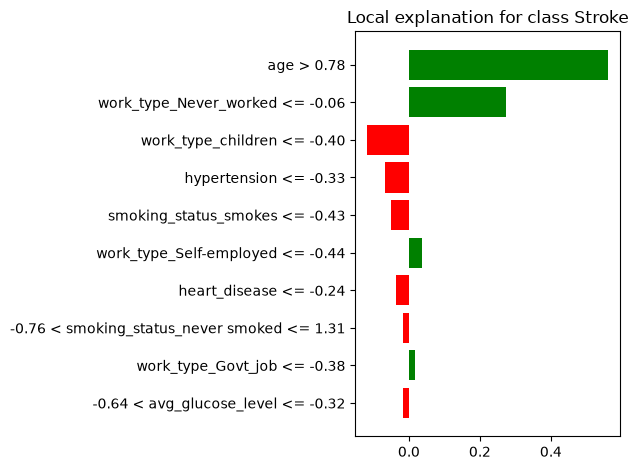

In [15]:
# ============================================================
# CELL 11 — LIME VISUALIZATION
# ============================================================

fig = lime_explanation.as_pyplot_figure()

plt.tight_layout()
plt.show()

In [16]:
# ============================================================
# CELL 12 — SAVE LIME EXPLANATION
# ============================================================

lime_output_path = os.path.join(
    PROCESSED_DIR,
    "lime_explanation.csv"
)

lime_df.to_csv(
    lime_output_path,
    index=False
)

print("LIME explanation saved successfully.")
print("Saved to:", lime_output_path)

LIME explanation saved successfully.
Saved to: d:\Explainable-AI-CDSS\datasets\processed\stroke\lime_explanation.csv


In [18]:
# ============================================================
# CELL 13 — FIND A STROKE-POSITIVE TEST PATIENT
# ============================================================

positive_indices = np.where(
    y_test.values == 1
)[0]

positive_index = positive_indices[0]

positive_patient = X_test.iloc[
    positive_index
].values

positive_actual = y_test.iloc[
    positive_index
]

positive_prediction = model.predict(
    X_test.iloc[[positive_index]]
)[0]

positive_probability = model.predict_proba(
    X_test.iloc[[positive_index]]
)[0][1]

print("Positive patient index:", positive_index)
print("Actual class:", positive_actual)
print("Predicted class:", positive_prediction)
print(
    "Stroke probability:",
    round(positive_probability * 100, 2),
    "%"
)

Positive patient index: 33
Actual class: 1
Predicted class: 1
Stroke probability: 87.55 %


In [19]:
# ============================================================
# CELL 14 — LIME FOR STROKE-POSITIVE PATIENT
# ============================================================

positive_explanation = explainer.explain_instance(
    positive_patient,
    model.predict_proba,
    num_features=10
)

positive_lime_df = pd.DataFrame(
    positive_explanation.as_list(),
    columns=["Feature", "LIME_Weight"]
)

positive_lime_df["Absolute_LIME"] = np.abs(
    positive_lime_df["LIME_Weight"]
)

positive_lime_df = positive_lime_df.sort_values(
    by="Absolute_LIME",
    ascending=False
).reset_index(drop=True)

display(positive_lime_df)

d:\Explainable-AI-CDSS\.venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


,Feature,LIME_Weight,Absolute_LIME
0,age > 0.78,0.555068,0.555068
1,gender_Other <= -0.02,0.257170,0.257170
2,work_type_Never_worked <= -0.06,0.152777,0.152777
3,work_type_children <= -0.40,-0.116325,0.116325
4,hypertension <= -0.33,-0.080770,0.080770
5,avg_glucose_level > 0.17,0.057757,0.057757
6,work_type_Self-employed <= -0.44,0.054060,0.054060
7,smoking_status_smokes <= -0.43,-0.035063,0.035063
8,heart_disease <= -0.24,-0.033176,0.033176
9,bmi > 0.50,0.016848,0.016848


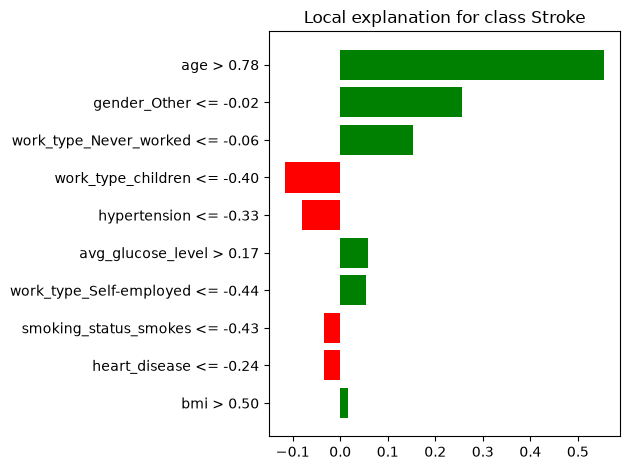

In [20]:
# ============================================================
# CELL 15 — POSITIVE PATIENT LIME PLOT
# ============================================================

positive_explanation.as_pyplot_figure()

plt.tight_layout()
plt.show()

In [21]:
# ============================================================
# CELL 16 — SAVE POSITIVE PATIENT EXPLANATION
# ============================================================

positive_output_path = os.path.join(
    PROCESSED_DIR,
    "lime_positive_patient.csv"
)

positive_lime_df.to_csv(
    positive_output_path,
    index=False
)

print("Positive patient LIME explanation saved.")
print("Saved to:", positive_output_path)

Positive patient LIME explanation saved.
Saved to: d:\Explainable-AI-CDSS\datasets\processed\stroke\lime_positive_patient.csv


In [22]:
# ============================================================
# CELL 17 — FINAL VERIFICATION
# ============================================================

print("=" * 70)
print("STROKE LIME EXPLAINABILITY — VERIFICATION")
print("=" * 70)

print("Model:", type(model).__name__)
print("Training samples:", len(X_train))
print("Test samples:", len(X_test))
print("Features:", len(feature_names))

print("\nPatient 0:")
print("Actual:", actual_class)
print("Prediction:", prediction)
print(
    "Probability:",
    round(probability * 100, 2),
    "%"
)

print("\nStroke-positive patient:")
print("Index:", positive_index)
print("Actual:", positive_actual)
print("Prediction:", positive_prediction)
print(
    "Probability:",
    round(positive_probability * 100, 2),
    "%"
)

print("\nLIME output:")
print(lime_output_path)

print("\nNotebook 26 completed successfully.")

STROKE LIME EXPLAINABILITY — VERIFICATION
Model: LogisticRegression
Training samples: 4088
Test samples: 1022
Features: 21

Patient 0:
Actual: 0
Prediction: 0
Probability: 46.15 %

Stroke-positive patient:
Index: 33
Actual: 1
Prediction: 1
Probability: 87.55 %

LIME output:
d:\Explainable-AI-CDSS\datasets\processed\stroke\lime_explanation.csv

Notebook 26 completed successfully.
